In [1]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [2]:
from langchain_groq import ChatGroq

llm = ChatGroq(model="qwen/qwen3.8-27b")

In [3]:
from typing import Annotated

from langchain_tavily import TavilySearch
from typing_extensions import TypedDict
from langchain_core.tools import tool

from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition

from langgraph.types import Command, interrupt

class State(TypedDict):
    messages:Annotated[list, add_messages]

graph_builder = StateGraph(State)

@tool
def human_assistance(query: str) -> str:
    """Request assistance from human"""
    human_response = interrupt({"query":query})
    return human_response["data"]

tool = TavilySearch(max_results=2)
tools = [tool, human_assistance]
llm_with_tools = llm.bind_tools(tools)

def Chatbot(state: State):
    message = llm_with_tools.invoke(state["messages"])
    return {"messages":message}

graph_builder.add_node("Chatbot", Chatbot)

tool_node = ToolNode(tools=tools)
graph_builder.add_node("tools", tool_node)

graph_builder.add_conditional_edges("Chatbot", tools_condition)
graph_builder.add_edge("tools", "Chatbot")
graph_builder.add_edge(START, "Chatbot")


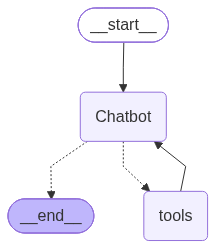

In [5]:
memory = MemorySaver()
graph = graph_builder.compile(checkpointer=memory)

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [6]:
user_input = "I need some expert guidance and assistance for building an AI agent. Could you request assistance for me?"
config = {"configurable": {"thread_id": "1"}}

events = graph.stream(
    {"messages": user_input},
    config,
    stream_mode="values",
)
for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()



================================ Human Message =================================

I need some expert guidance and assistance for building an AI agent. Could you request assistance for me?
================================== Ai Message ==================================

Understood. Let's get you the expert help you need.

Let me first gather some context on current best practices for AI agent development so I can frame your request effectively, and then I'll connect you with human assistance.
Tool Calls:
  tavily_search (dkw8v9j4y)
 Call ID: dkw8v9j4y
  Args:
    end_date: None
    exclude_domains: []
    include_domains: []
    include_images: None
    query: best practices for building AI agents 2025 architecture frameworks tool use
    search_depth: None
    start_date: None
    time_range: None
    topic: None
  human_assistance (xar3v4yfc)
 Call ID: xar3v4yfc
  Args:
    query: I need expert guidance and assistance for building an AI agent. I'm looking for help with the overall arc

In [7]:
human_response = (
    "We, the experts are here to help! We'd recommend you to read the book Generative AI with LangChain by Ben Auffarth to build your agents."
    " It's much more reliable and extensible as you will get a comprehensive solution to problems rather than a small fix for building autonomous agents."
)

human_command = Command(resume={"data":human_response})
events = graph.stream(human_command, config, stream_mode = "values")
for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()


================================== Ai Message ==================================

Understood. Let's get you the expert help you need.

Let me first gather some context on current best practices for AI agent development so I can frame your request effectively, and then I'll connect you with human assistance.
Tool Calls:
  tavily_search (dkw8v9j4y)
 Call ID: dkw8v9j4y
  Args:
    end_date: None
    exclude_domains: []
    include_domains: []
    include_images: None
    query: best practices for building AI agents 2025 architecture frameworks tool use
    search_depth: None
    start_date: None
    time_range: None
    topic: None
  human_assistance (xar3v4yfc)
 Call ID: xar3v4yfc
  Args:
    query: I need expert guidance and assistance for building an AI agent. I'm looking for help with the overall architecture and design of an AI agent, including considerations such as: (1) choosing an appropriate framework/stack (e.g., LangGraph, LangChain, AutoGen, CrewAI, OpenAI Agents SDK, or a cus